# Аналіз даних: клавіатурний почерок

**Що ми робимо.** У нас є таблиця `features.csv`: один рядок = одна спроба набрати фразу `SS123+`.
Хочемо подивитися на дані й відповісти на питання: **чи справді люди друкують по-різному?**

Кроки: 1) завантажити дані, 2) порахувати спроби, 3) прибрати дивні спроби, 4) намалювати графіки, 5) зробити висновок.

Щоб запустити все: меню **Run → Run All**. Якщо додали нові дані, спочатку виконайте `python features.py`.

## 1. Завантажуємо дані

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("data/features.csv")

df["user"] = "u" + df["user_id"].astype("category").cat.codes.astype(str)
df = df.drop(columns="user_id")

print("Спроб:", len(df))
print("Учасників:", df["user"].nunique())
df.head()

Спроб: 150
Учасників: 27


,session_id,attempt_id,total_ms,speed_cps,backspace_count,error_count,dwell_1,dwell_2,dwell_3,dwell_4,...,uu_5,dwell_mean,dwell_median,dwell_std,dwell_cv,ud_mean,ud_median,ud_std,ud_cv,user
0,k5637fzpmvz0isb1,183kb9x0mvz0qyk8,2348.7,2.554605,0,0,64.6,57.7,92.5,71.6,...,626.6,68.266667,65.65,13.148181,0.192600,387.82,200.8,307.521287,0.792948,u12
1,5t2eaxnjmvz0m4r5,1bshwrzkmvz0r12b,2030.1,2.955519,0,0,95.2,95.7,99.4,99.8,...,875.8,99.583333,99.60,3.721514,0.037371,286.52,142.4,287.672369,1.004022,u16
2,g5jb9bz6mvz0jpnb,2aiym7nhmvz0oooh,2768.5,2.167239,0,0,86.3,78.0,98.5,88.4,...,943.2,82.433333,82.15,10.763209,0.130569,454.78,163.3,440.334069,0.968235,u17
3,5t2eaxnjmvz0m4r5,2n9062ncmvz0ombg,4461.7,1.344779,0,0,314.5,266.3,104.0,113.5,...,1974.7,180.533333,148.20,91.462444,0.506624,675.70,250.9,708.338637,1.048303,u16
4,05wwsk6bmvz0iygd,2usojbiomvz0nrt9,3912.1,1.533703,0,0,98.3,109.3,89.6,93.7,...,1386.1,92.033333,91.65,11.372540,0.123570,671.98,531.1,514.348425,0.765422,u5


## 2. Скільки спроб у кожного учасника

За технічним завданням потрібно **не менше 30 спроб** на людину.

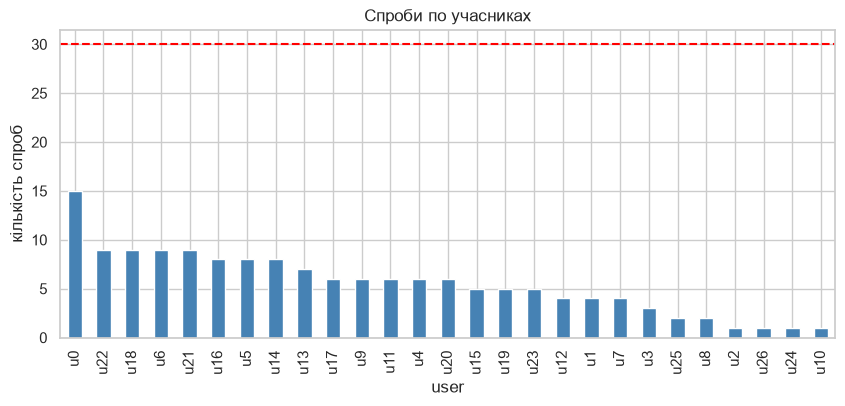

Найбільше спроб в однієї людини: 15
Учасників, у яких 30 і більше спроб: 0


In [2]:
counts = df["user"].value_counts()

plt.figure(figsize=(10, 4))
counts.plot(kind="bar", color="steelblue")
plt.axhline(30, color="red", linestyle="--")   # червона лінія: потрібно 30
plt.title("Спроби по учасниках")
plt.ylabel("кількість спроб")
plt.savefig("reports/eda/1_спроби.png", dpi=150, bbox_inches="tight")
plt.show()

print("Найбільше спроб в однієї людини:", counts.max())
print("Учасників, у яких 30 і більше спроб:", (counts >= 30).sum())

## 3. Чи є пропуски в таблиці

In [3]:
print("Порожніх клітинок:", df.isna().sum().sum())

Порожніх клітинок: 0


## 4. Прибираємо дивні спроби (викиди)

Іноді людина відволіклась, і спроба тривала 15 секунд замість 3. Такі спроби псують картину.

Правило (метод IQR):
- Q1 і Q3 це «нижня» і «верхня» чверті часу набору;
- IQR = Q3 − Q1;
- дивною вважаємо спробу, час якої менший за `Q1 − 1.5·IQR` або більший за `Q3 + 1.5·IQR`.

In [4]:
q1 = df["total_ms"].quantile(0.25)
q3 = df["total_ms"].quantile(0.75)
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

clean = df[(df["total_ms"] >= low) & (df["total_ms"] <= high)]

print(f"Нормальний час набору: від {low:.0f} до {high:.0f} мс")
print(f"Видалено дивних спроб: {len(df) - len(clean)} із {len(df)}")

clean.to_csv("data/features_clean.csv", index=False)   # зберігаємо чисту таблицю

Нормальний час набору: від 444 до 5288 мс
Видалено дивних спроб: 9 із 150


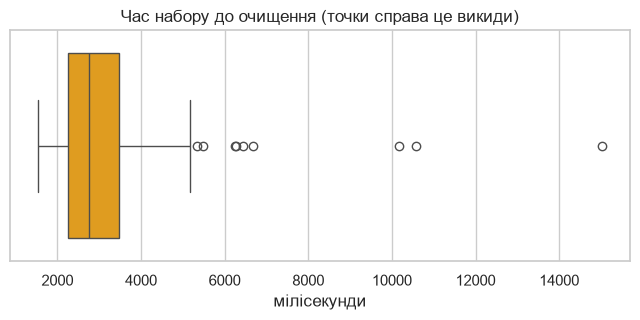

In [5]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["total_ms"], color="orange")
plt.title("Час набору до очищення (точки справа це викиди)")
plt.xlabel("мілісекунди")
plt.savefig("reports/eda/2_викиди.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Скільки людина тримає кожну клавішу (dwell)

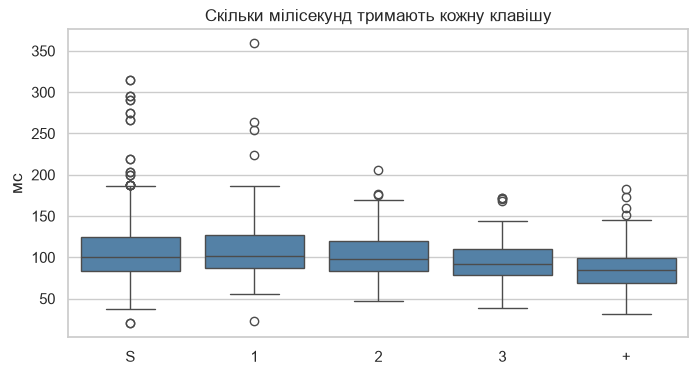

In [6]:
keys = ["S", "S", "1", "2", "3", "+"]
dwell = clean[["dwell_1", "dwell_2", "dwell_3", "dwell_4", "dwell_5", "dwell_6"]]
dwell.columns = keys

plt.figure(figsize=(8, 4))
sns.boxplot(data=dwell, color="steelblue")
plt.title("Скільки мілісекунд тримають кожну клавішу")
plt.ylabel("мс")
plt.savefig("reports/eda/3_dwell.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Чи відрізняються люди між собою

Беремо тільки учасників, у яких хоча б 5 спроб, і порівнюємо **середній час утримання клавіші**.
Якщо «коробки» розташовані на різній висоті, то люди друкують по-різному.

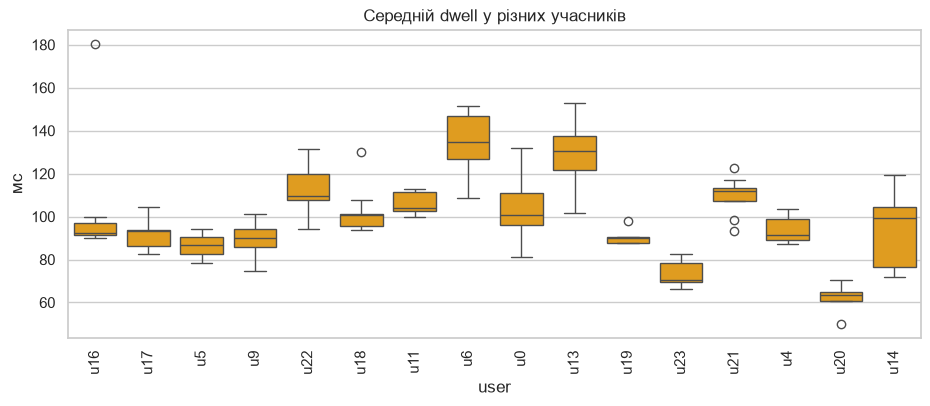

In [7]:
many = clean["user"].value_counts()
many = many[many >= 5].index
part = clean[clean["user"].isin(many)]

plt.figure(figsize=(11, 4))
sns.boxplot(data=part, x="user", y="dwell_mean", color="orange")
plt.title("Середній dwell у різних учасників")
plt.ylabel("мс")
plt.xticks(rotation=90)
plt.savefig("reports/eda/4_люди.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Які ознаки схожі між собою (кореляція)

Число від −1 до 1: біля 1 означає «одна росте, і друга росте», біля 0 означає «ніяк не пов'язані».

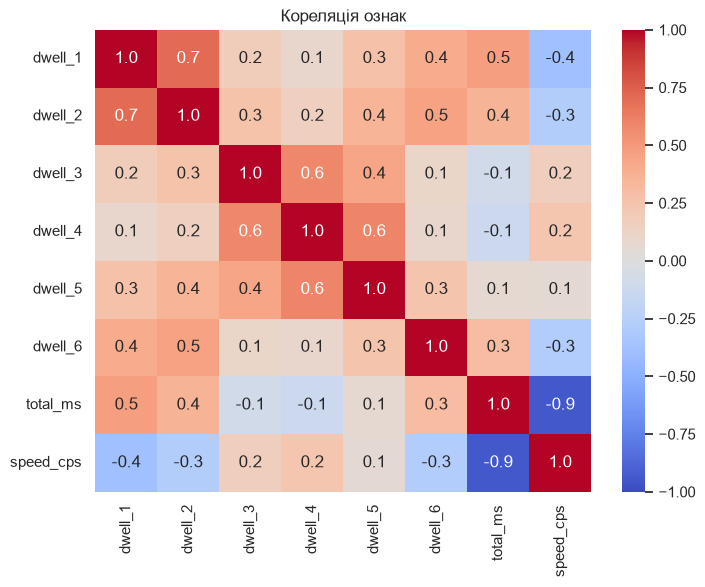

In [8]:
cols = ["dwell_1", "dwell_2", "dwell_3", "dwell_4", "dwell_5", "dwell_6", "total_ms", "speed_cps"]

plt.figure(figsize=(8, 6))
sns.heatmap(clean[cols].corr(), annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Кореляція ознак")
plt.savefig("reports/eda/5_кореляція.png", dpi=150, bbox_inches="tight")
plt.show()